In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

B = "../data/lake/bronze" # ".." means one folder up from notebooks/
products = pd.read_csv(f"{B}/makeup_products.csv")
reviews = pd.read_csv(f"{B}/makeup_reviews.csv",low_memory=False)
print(len(products),len(reviews))

print(products.shape)
print(reviews.shape)

print(products.head())
print(reviews.head())

print(products.info())
print(reviews.info())

1373 314029
(1373, 35)
(314029, 27)
   product_link_id                                       product_link  \
0                8  https://www.ulta.com/p/futurist-skin-tint-seru...   
1               13  https://www.ulta.com/p/dior-forever-fluid-skin...   
2               22  https://www.ulta.com/p/barepro-24hr-wear-skin-...   
3               32  https://www.ulta.com/p/futurist-hydra-rescue-m...   
4               15  https://www.ulta.com/p/mini-cc-cream-with-spf-...   

     category    item_id                                       product_name  \
0         NaN  2612458.0         Futurist Skin Tint Serum Foundation SPF 20   
1         NaN  2605037.0            Dior Forever Fluid Skin Glow Foundation   
2         NaN  2619782.0  BAREPRO 24HR Wear Skin-Perfecting Matte Liquid...   
3         NaN  2559137.0  Futurist Hydra Rescue Moisturizing Foundation ...   
4  Foundation  2603710.0                        Mini CC+ Cream with SPF 50+   

             brand  price  num_shades  rating  num

In [13]:
def profile(df):
 return pd.DataFrame({
 "dtype": df.dtypes.astype(str), # the kind of data
 "non-null":df.notna().sum(), # how many cells are filled
 "null_pct": (df.isna().mean() * 100).round(1), # % of cells that are empty
 "unique": df.nunique(), # how many different values
 "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else
None),
 })

profile(reviews)

,dtype,non-null,null_pct,unique,example
unique_review_id,int64,314029,0.0,314029,1
product_link_id,int64,314029,0.0,1403,8
review_id,int64,314029,0.0,56999,521867580
type,object,314029,0.0,3,image
id,float64,261849,16.6,46082,521867563.0
ugc_id,float64,52180,83.4,25429,525372766.0
legacy_id,float64,52180,83.4,25429,402725357.0
internal_review_id,int64,314029,0.0,25430,-1
headline,object,314029,0.0,38626,2C3 Fresco
nickname,object,312730,0.4,31412,Dinara


In [14]:
print(products.columns.tolist())
print(reviews.columns.tolist())

['product_link_id', 'product_link', 'category', 'item_id', 'product_name', 'brand', 'price', 'num_shades', 'rating', 'num_reviews', 'description', 'pros', 'cons', 'best_uses', 'describe_yourself', 'review_star_1', 'review_star_2', 'review_star_3', 'review_star_4', 'review_star_5', 'rating_star_1', 'rating_star_2', 'rating_star_3', 'rating_star_4', 'rating_star_5', 'rating_count', 'review_count', 'average_rating', 'recommended_ratio', 'native_review_count', 'native_sampling_review_count', 'native_community_content_review_count', 'syndicated_review_count', 'faceoff_negative', 'faceoff_positive']
['unique_review_id', 'product_link_id', 'review_id', 'type', 'id', 'ugc_id', 'legacy_id', 'internal_review_id', 'headline', 'nickname', 'created_date', 'updated_date', 'rating', 'helpful_votes', 'not_helpful_votes', 'uri', 'comments', 'locale', 'location', 'bottom_line', 'product_page_id', 'upc', 'gtin', 'is_staff_reviewer', 'is_verified_buyer', 'is_verified_reviewer', 'helpful_score']


In [15]:
checks = {

    # PRODUCTS DATASET

    "products: duplicate rows":
        products.duplicated().sum(),

    "products: duplicate product_link_id":
        products["product_link_id"].duplicated().sum(),

    "products: missing brand":
        products["brand"].isna().sum(),

    "products: missing category":
        products["category"].isna().sum(),

    "products: missing price":
        products["price"].isna().sum(),

    "products: invalid price <= 0":
        (products["price"] <= 0).sum(),

    "products: missing rating":
        products["rating"].isna().sum(),

    "products: invalid rating (<0 or >5)":
        ((products["rating"] < 0) | (products["rating"] > 5)).sum(),

    # REVIEWS DATASET

    "reviews: duplicate rows":
        reviews.duplicated().sum(),

    "reviews: duplicate review_id":
        reviews["review_id"].duplicated().sum(),

    "reviews: missing nickname":
        reviews["nickname"].isna().sum(),

    "reviews: missing headline":
        reviews["headline"].isna().sum(),

    "reviews: missing comments":
        reviews["comments"].isna().sum(),

    "reviews: missing rating":
        reviews["rating"].isna().sum(),

    "reviews: invalid rating (<1 or >5)":
        ((reviews["rating"] < 1) | (reviews["rating"] > 5)).sum(),

    # REFERENTIAL INTEGRITY

    "reviews: unknown product_link_id":
        (~reviews["product_link_id"].isin(products["product_link_id"])).sum(),

    # POSSIBLE PII RISKS

    "reviews: nickname present":
        reviews["nickname"].notna().sum(),

    "reviews: email in comments":
        reviews["comments"].astype(str).str.contains(
            r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
            na=False
        ).sum(),

    "reviews: phone number in comments":
        reviews["comments"].astype(str).str.contains(
            r"01\d-?\d{7,8}|\+60\d+",
            na=False
        ).sum(),

}

pd.Series(checks, name="issues").to_frame()

,issues
products: duplicate rows,0
products: duplicate product_link_id,0
products: missing brand,443
products: missing category,22
products: missing price,0
products: invalid price <= 0,0
products: missing rating,141
products: invalid rating (<0 or >5),0
reviews: duplicate rows,0
reviews: duplicate review_id,257030


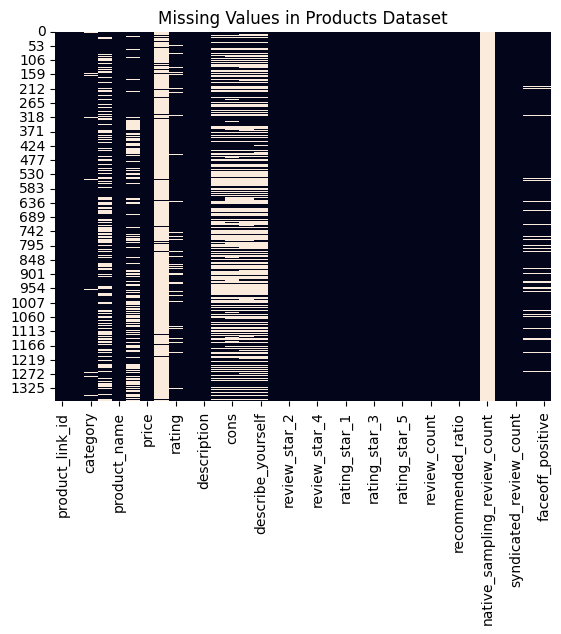

In [16]:
sns.heatmap(products.isnull(), cbar=False)
plt.title("Missing Values in Products Dataset")
plt.show()

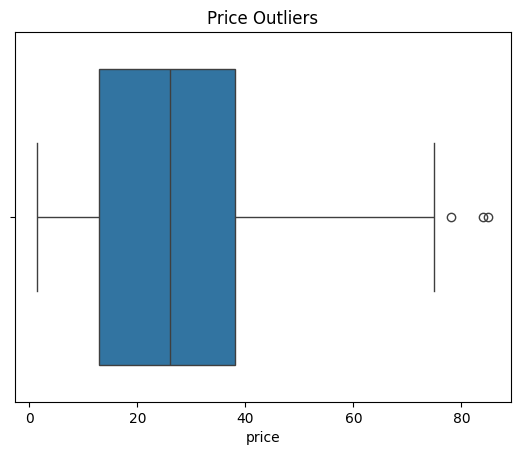

In [17]:
sns.boxplot(x=products["price"])
plt.title("Price Outliers")
plt.show()

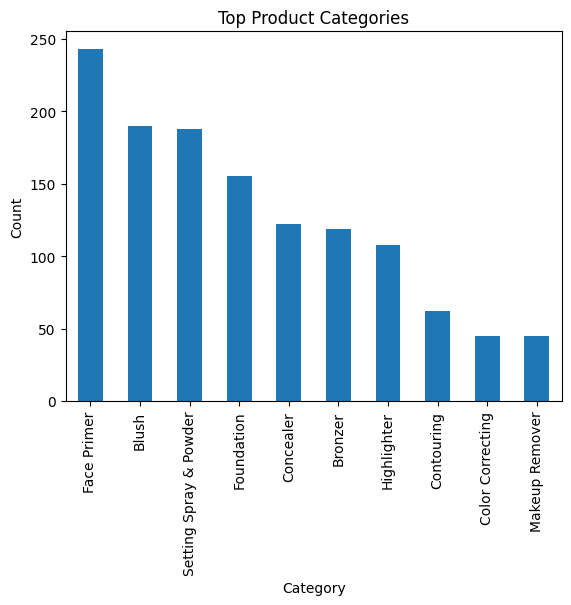

In [18]:
products["category"].value_counts().head(10).plot(
kind="bar"
)
plt.title("Top Product Categories")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

In [19]:
# DATA QUALITY CHECKS

# Missing values
print("PRODUCTS - Missing Values")
print(products.isnull().sum().sort_values(ascending=False))

print("\nREVIEWS - Missing Values")
print(reviews.isnull().sum().sort_values(ascending=False))


# Duplicate records
print("\nDuplicate Checks")
print("Products duplicate rows:", products.duplicated().sum())
print("Duplicate product IDs:", products["product_link_id"].duplicated().sum())

print("Reviews duplicate rows:", reviews.duplicated().sum())
print("Duplicate unique review IDs:",
      reviews["unique_review_id"].duplicated().sum())
print("Repeated review IDs:",
      reviews["review_id"].duplicated().sum())


# Invalid values
print("\nInvalid Values")
print("Invalid product prices:", (products["price"] <= 0).sum())

print("Invalid product ratings:",
      ((products["rating"] < 0) | (products["rating"] > 5)).sum())

print("Invalid review ratings:",
      ((reviews["rating"] < 1) | (reviews["rating"] > 5)).sum())


# Referential integrity
unknown_products = ~reviews["product_link_id"].isin(
    products["product_link_id"]
)

print("\nUnmatched Product References:", unknown_products.sum())


# Outlier detection using IQR
Q1 = products["price"].quantile(0.25)
Q3 = products["price"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = products[
    (products["price"] < lower) |
    (products["price"] > upper)
]

print("\nPrice Outliers:", len(outliers))
print(outliers[["product_name", "price"]])


# Invalid update timestamps
invalid_dates = reviews["updated_date"].astype(str).str.startswith("1970")

print("\nInvalid Update Dates:", invalid_dates.sum())

PRODUCTS - Missing Values
native_sampling_review_count             1373
num_shades                               1309
best_uses                                 730
cons                                      698
describe_yourself                         683
pros                                      618
item_id                                   520
brand                                     443
rating                                    141
faceoff_negative                          129
faceoff_positive                          129
category                                   22
num_reviews                                 1
product_link                                0
product_link_id                             0
review_star_1                               0
description                                 0
product_name                                0
price                                       0
review_star_4                               0
review_star_3                               0
review_s

In [20]:
# DATA CLEANING

products_clean = products.copy()
reviews_clean = reviews.copy()

# Handle missing categorical values
products_clean["brand"] = products_clean["brand"].fillna("Unknown")
products_clean["category"] = products_clean["category"].fillna("Unknown")

# Convert invalid update timestamps to missing values
reviews_clean.loc[
    reviews_clean["updated_date"].astype(str).str.startswith("1970"),
    "updated_date"
] = np.nan

# Flag unmatched product references
reviews_clean["unmatched_product"] = ~reviews_clean[
    "product_link_id"
].isin(products_clean["product_link_id"])

# Flag price outliers
products_clean["price_outlier"] = (
    (products_clean["price"] < lower) |
    (products_clean["price"] > upper)
)

print("Data cleaning completed.")
print("Products:", products_clean.shape)
print("Reviews:", reviews_clean.shape)

Data cleaning completed.
Products: (1373, 36)
Reviews: (314029, 28)


### Data Profiling and Issue Handling

The makeup dataset was examined to identify missing values, duplicate records, outliers, invalid values, and inconsistencies between the products and reviews datasets.

**3.1 Missing Values**

Several columns contain missing values, particularly in optional product descriptions and customer review information.

- In the products dataset, 443 brand values and 22 category values are missing.
- The rating column contains 141 missing values.
- In the reviews dataset, 261,865 comments are missing, representing approximately 83.39% of the records.
- Customer nicknames have 1,299 missing values.

**Handling:** Missing brand and category values will be labelled as "Unknown" where needed. Missing product ratings will remain empty because assigning an estimated rating could misrepresent the actual customer feedback. Missing comments will also be retained because reviews without written comments may still contain useful rating information.

**3.2 Outliers**

Outliers in product prices were identified using the Interquartile Range (IQR) method and visualised using a boxplot.

The price distribution has:
- Q1 = $12.99
- Q3 = $38.00
- IQR = $25.01
- Upper boundary = $75.515

Three products have prices above the upper boundary ($78, $84 and $85).

**Handling:** These values will be retained because they may represent premium makeup products rather than incorrect prices. However, they will be flagged for further inspection.

**3.3 Other Data Quality Issues**

Other issues identified include:

- Duplicate review IDs: Some review_id values appear multiple times. However, unique_review_id is unique across the dataset, so review_id should not be treated as the primary key.
- Referential integrity: 8,298 reviews contain product_link_id values that cannot be matched to the products dataset.
- Invalid timestamps: 261,849 updated_date values contain a default 1970 timestamp, which may represent unavailable or incorrectly recorded update dates.
- Missing product information: Some products have incomplete brand, category, and rating information.

**Handling:** Duplicate records will be checked using the complete rows and unique_review_id. Unmatched product references will be flagged instead of automatically deleted. Invalid timestamps will be converted to missing values for accurate date analysis.

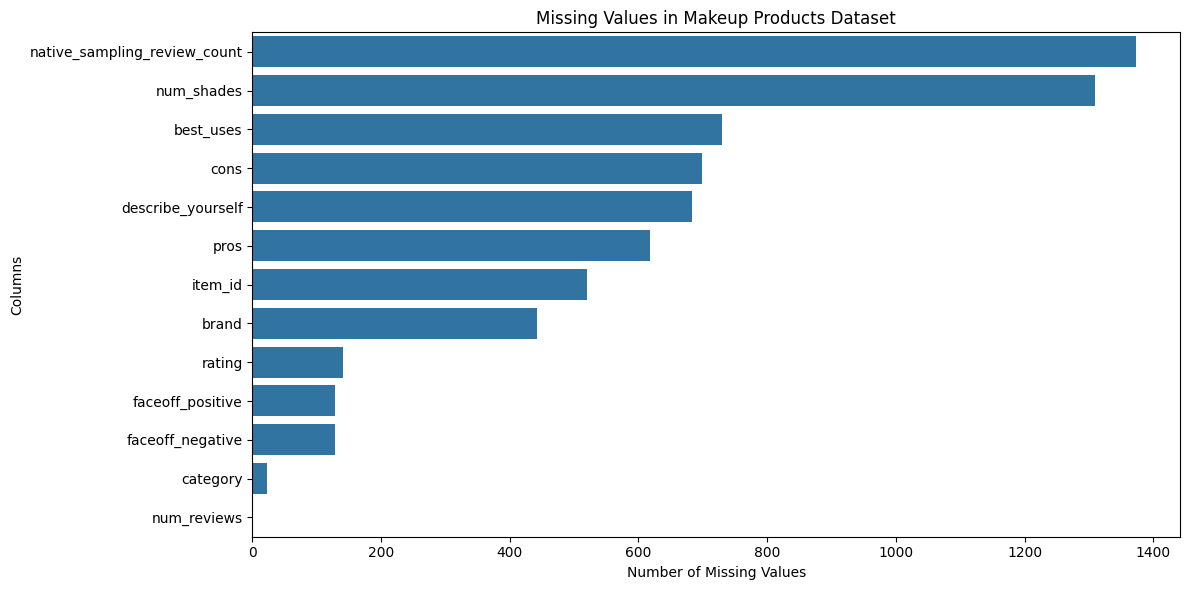

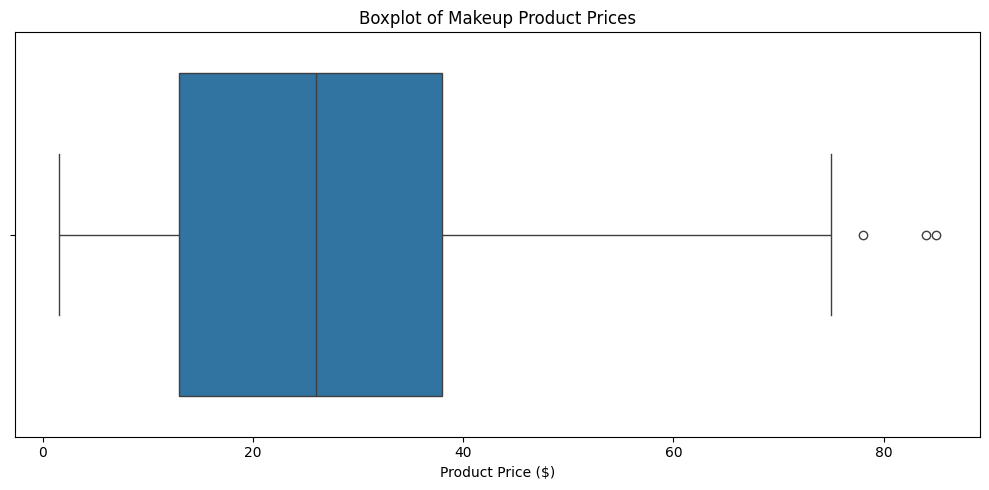

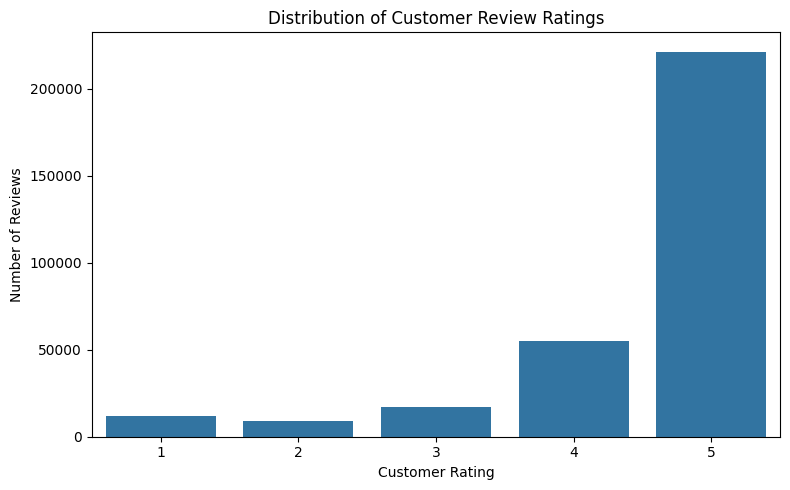

In [21]:
# CHART 1: MISSING VALUES

plt.figure(figsize=(12, 6))

missing = products.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

sns.barplot(x=missing.values, y=missing.index)

plt.title("Missing Values in Makeup Products Dataset")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()


# CHART 2: PRICE OUTLIERS

plt.figure(figsize=(10, 5))

sns.boxplot(x=products["price"])

plt.title("Boxplot of Makeup Product Prices")
plt.xlabel("Product Price ($)")
plt.tight_layout()
plt.show()


# CHART 3: CUSTOMER RATING DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews,
    x="rating"
)

plt.title("Distribution of Customer Review Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

### Exploratory (Diagnostic) Charts

Several diagnostic visualisations were created to identify data quality problems in the makeup dataset.

**4.1 Missing Values Analysis**

A missing-value chart is used to identify columns with incomplete information. The products dataset contains missing values in brand, category, rating, and other optional product information. The reviews dataset has a particularly high percentage of missing comments and customer information.

**4.2 Product Price Outliers**

A boxplot is used to identify unusual product prices. Three products were identified as potential outliers using the IQR method. These values are retained because expensive products may be legitimate.

**4.3 Customer Review Rating Distribution**

A bar chart is used to examine the distribution of customer ratings. The dataset contains a high number of five-star reviews, indicating a possible imbalance in customer feedback.

These visualisations help identify data quality problems before using the dataset for further analysis.